# 01 · Read the record before testing it

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p04_tide_fouling/notebooks/01_the_record.ipynb)

**Project 4 — the moon, the sun and a seawater membrane.** A seawater plant draws from the sea, and
the sea follows the moon; a plant that runs on solar power stops at night and starts every morning.
Three questions follow for the membrane that pre-treats the water: does its fouling follow the
**tide**, the **hour of the day**, or the **morning restart**? Each was declared before it was tested.

This notebook comes first: what the public record is, and what an audit found before any test was
run. Two of its findings changed what the tests could use.

**Data:** a public seawater ultrafiltration (UF) pilot record, pre-treatment for a reverse-osmosis pilot, 2012–2015: Zenodo [4630769](https://zenodo.org/records/4630769), also Dryad [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B), CC0. The site is not named here. The notebooks read the tables committed in `results/`; the 356 MB raw archive is needed only where a cell says so.

Script version: `step1_audit.py` · record: `VALIDATION.md`, section 1.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 4 pull request is merged, use "p04-tide-fouling"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P4 = ROOT / "projects" / "p04_tide_fouling"
RES = P4 / "results"

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, SUN = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#f2c14e"

def load(name):
    """A committed result file from projects/p04_tide_fouling/results/."""
    return json.loads((RES / name).read_text())

## 0. What the audit kept

`step1_audit.py` reads every file in the archive; its findings are committed as
`results/step1_audit.json` and `results/runs.parquet`. To redo the audit from the raw archive, set
`FULL_AUDIT = True` in the next cell (a 356 MB download from Zenodo, about ten minutes in Colab).

In [2]:
FULL_AUDIT = False
if FULL_AUDIT:
    if "google.colab" in sys.modules:                       # a tool that opens .rar archives
        subprocess.run("apt-get -qq install -y libarchive-tools > /dev/null", shell=True, check=True)
    from chemai.data.uf_pilot import audit_files, download_archive, extract_archive
    extract_archive(download_archive())                     # checks the published md5 first
    a = audit_files()
    print(len(a), "files;", int(a.has_clock.sum()), "with a clock;",
          int((a.has_clock & ~a.clock_trusted).sum()), "clocks not trusted")

audit = load("step1_audit.json")
runs = pd.read_parquet(RES / "runs.parquet")
print(f"{audit['files']} files; {audit['with_clock']} carry a logged clock")
pd.Series(audit["by_layout"], name="files").rename_axis("layout").to_frame()

180 files; 150 carry a logged clock


,files
layout,
csv_clock,149
sheet,27
csv_noclock,3
csv_clock_noheader,1


Four layouts in one archive: comma-separated logs with a clock, spreadsheets, three logs with no
clock at all, one with no header. Only a clock lets a log be lined up with the moon or the sun, so
the 30 files without one are out.

## 1. Can the clock be trusted?

Each file is named for a day. Where the logged clock starts on a different day, either the name or
the clock is wrong, and nothing says which — so the file is excluded.

In [3]:
pd.DataFrame(audit["clock_not_trusted"]).rename(columns={"clock_offset_days": "clock minus file name (days)"})

,split,file,clock minus file name (days)
0,training,20120308.csv,106.37
1,training,20140701.csv,-174.11
2,training,20140705.csv,-3.33
3,test,20120325.csv,88.47
4,test,20121022.csv,-6.36
5,test,20130626.csv,-364.51


Six files: one is a year out, two half a year, three a few days. A test that lines data up with
the moon at the scale of hours cannot carry a clock that is days wrong.

Five files also have malformed lines (a few rows with too many fields). They are skipped and counted,
not repaired:

In [4]:
pd.DataFrame(audit["malformed_lines"])

,split,file,bad_lines
0,training,20120723.csv,82
1,training,20120725.csv,7
2,training,20120726.csv,8
3,training,20140206.csv,4
4,training,20140329.csv,1


## 2. Is the clock local time?

The tide test does not care which time zone the logger used — it fits the phase. The sun test does:
"09:00" has to mean the morning. A check that needs no metadata: in every run of 48 hours or more,
find the hour at which the water is warmest on average. Seawater warms in the afternoon.

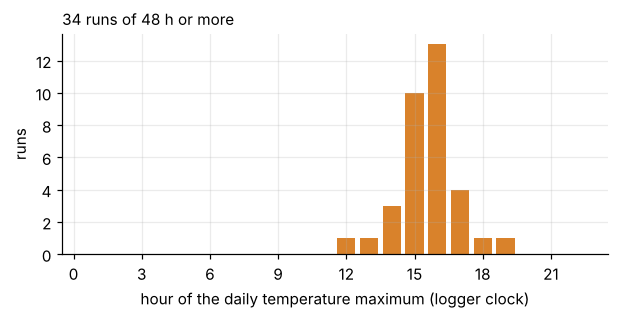

In [5]:
h = pd.Series(audit["temperature_peak_hour"]["histogram"]).rename(index=float).sort_index()
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.bar(h.index, h.values, color=ORANGE, width=0.8)
ax.set_xlim(-0.5, 23.5); ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hour of the daily temperature maximum (logger clock)"); ax.set_ylabel("runs")
ax.set_title(f"{audit['temperature_peak_hour']['runs']} runs of 48 h or more", loc="left", fontsize=10)
plt.show()

All 34 peak between 12:00 and 19:00, most at 15–16 h: the logger ran on local civil time. Daylight
saving is then removed (`to_standard_time`), so a given hour means the same sun all year.

## 3. Runs, episodes, and the published split

In [6]:
print(f"kept: {audit['trusted_and_long_enough']} runs of 6 h or more, {audit['hours_total']:,} h, "
      f"{audit['first_and_last'][0][:10]} to {audit['first_and_last'][1][:10]}")
print("episodes (runs less than 30 min apart joined):", audit["episodes"])
runs.groupby("split").hours.agg(runs="count", hours="sum").round(1)

kept: 107 runs of 6 h or more, 5,105.8 h, 2012-06-23 to 2015-04-01


episodes (runs less than 30 min apart joined): 87


,runs,hours
split,,
test,15,889.1
training,92,4216.7


The depositors split their files into `training/` and `test/`. A split is only useful for
testing if the test files are separate in time — otherwise the "test" is the same water a few
minutes later. They are not:

In [7]:
mixed = runs[runs.episode.isin(audit["episodes_mixing_training_and_test"])].sort_values("t_start")
mixed[["split", "file", "t_start", "t_end", "hours", "episode"]].round(2)

,split,file,t_start,t_end,hours,episode
88,training,20131219.csv,2013-12-19 11:05:53.004796920,2013-12-26 12:06:02.082527974,169.00,40
169,test,20131226.csv,2013-12-26 12:33:53.598009591,2013-12-30 15:26:14.796470417,98.87,40
175,test,20140625.csv,2014-06-25 16:04:56.141558235,2014-06-26 14:19:16.141612584,22.24,60
110,training,20140626.csv,2014-06-26 14:19:26.141635035,2014-06-27 11:43:06.141619338,21.39,60
111,training,20140627.csv,2014-06-27 11:43:16.141641798,2014-06-28 08:56:46.141641297,21.22,60
112,training,20140628.csv,2014-06-28 08:56:56.141577625,2014-06-29 08:46:56.141097902,23.83,60
113,training,20140629.csv,2014-06-29 08:47:06.141033600,2014-06-30 08:23:46.141094209,23.61,60
114,training,20140630.csv,2014-06-30 08:23:56.152780497,2014-07-01 08:03:26.141039732,23.66,60


Three `test/` files continue a training run without a break. This project therefore never uses the
published split to claim anything; its confirmation splits **in time** (before and after
2014-01-01), and the published split is reported beside it, not relied on.

## 4. What the turbidity sensor was reading

Turbidity would be the natural mechanism for a tide effect: the tide stirs the seabed. But the
sensor was not always on the feed:

In [8]:
t = runs.assign(year=runs.t_start.dt.year).groupby(["year", "turbidity_reads"]).hours.sum().unstack(fill_value=0)
t.round(0)

turbidity_reads,feed,filtrate,none
year,,,
2012,0.0,0.0,175.0
2013,1518.0,143.0,0.0
2014,0.0,1075.0,1110.0
2015,0.0,0.0,1085.0


It read the **feed** (median at least 0.20 NTU) only in 2013, read the clear filtrate in other
years, or had no signal. So the turbidity test (S1) uses 2013 only, and the main question is asked
of the membrane itself: its fouling rate.

## 5. The record at a glance

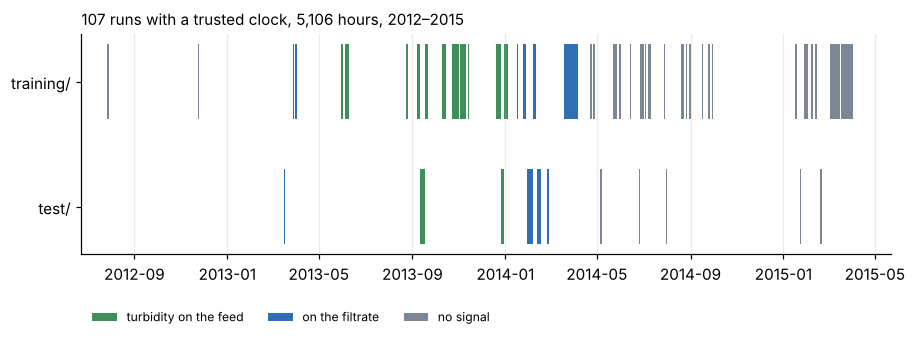

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 2.6))
colors = {"feed": GREEN, "filtrate": BLUE, "none": MUTED}
for r in runs.itertuples():
    y = 1 if r.split == "training" else 0
    ax.barh(y, (r.t_end - r.t_start).total_seconds() / 86400, left=r.t_start, height=0.6,
            color=colors[r.turbidity_reads], edgecolor="none")
for k, c in colors.items():
    ax.barh(np.nan, 0, color=c, label={"feed": "turbidity on the feed", "filtrate": "on the filtrate", "none": "no signal"}[k])
ax.set_yticks([0, 1], ["test/", "training/"]); ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0, -0.2))
ax.set_title("107 runs with a trusted clock, 5,106 hours, 2012–2015", loc="left", fontsize=10)
plt.show()

**What the audit settled before any test:** 107 runs, 5,106 hours with a clock that can be lined
up with the sky; the published test split is not a test; turbidity covers one year. The next
notebook turns the runs into a fouling rate.